# 1. Matrix product states

**Goal.** Write a many-body state as a chain of small tensors, see why that is cheap for ground states, and read off entanglement from it.

*Further reading:* U. Schollwöck, [arXiv:1008.3477](https://arxiv.org/abs/1008.3477), Sec. 4; R. Orús, [arXiv:1306.2164](https://arxiv.org/abs/1306.2164) (a gentle introduction).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import dmrg

## Intuition: one SVD per cut

A state of $L$ spins has $2^L$ amplitudes $\psi_{s_1 s_2 \dots s_L}$. Reshape it as a matrix with rows $s_1$ and columns $(s_2\dots s_L)$ and take an SVD:

$$\psi_{s_1, (s_2\dots s_L)} = \sum_a U_{s_1 a}\, S_a\, V^\dagger_{a, (s_2 \dots s_L)}.$$

The singular values $S_a$ are the **Schmidt values** of the cut after site 1. Keep $U$ as the first tensor, carry $S V^\dagger$ along, and split off site 2 with another SVD, and so on. The result is

$$\psi_{s_1 \dots s_L} = A^{s_1}_{1}\,A^{s_2}_{2} \cdots A^{s_L}_{L},$$

a product of matrices, one per site: a **matrix product state**. In code each $A$ is a 3-index array `A[left, phys, right]`.

The matrices can be as large as $2^{L/2}$ in the middle of the chain, so this is exact but not yet cheap. The point is that **ground states of gapped local Hamiltonians obey an area law**: the entanglement across any cut is bounded, the Schmidt values fall off fast, and keeping the largest $\chi$ of them is an excellent approximation (Hastings, [arXiv:0705.2024](https://arxiv.org/abs/0705.2024)).

In [2]:
import inspect

print(inspect.getsource(dmrg.from_dense))

def from_dense(psi, L, d=2, chi_max=None):
    """Exact (or truncated) MPS of a state vector by successive SVDs, left to right.

    Each SVD splits off one site: psi[(left bond, s), (rest)] = U S Vh. U becomes
    the site tensor (a left isometry) and S Vh is carried on to the next step.
    With ``chi_max=None`` nothing is truncated and the MPS is exact.
    """
    chi_max = chi_max or d**L
    mps = []
    rest = np.asarray(psi).reshape(1, -1)  # rest[left bond, remaining physical indices]
    for _ in range(L - 1):
        chi_l = rest.shape[0]
        U, S, Vh, _ = truncated_svd(rest.reshape(chi_l * d, -1), chi_max, cutoff=0)
        mps.append(U.reshape(chi_l, d, -1))
        rest = S[:, None] * Vh
    mps.append(rest.reshape(rest.shape[0], d, 1))
    return mps



In [3]:
L = 8
psi = np.random.default_rng(0).normal(size=2**L)
psi /= np.linalg.norm(psi)

mps = dmrg.from_dense(psi, L)
print("tensor shapes:", [A.shape for A in mps])
print("exact?", np.allclose(dmrg.to_dense(mps), psi))

tensor shapes: [(1, 2, 2), (2, 2, 4), (4, 2, 8), (8, 2, 16), (16, 2, 8), (8, 2, 4), (4, 2, 2), (2, 2, 1)]
exact? True


A random state has bond dimensions $1, 2, 4, 8, 16, 8, 4, 2, 1$: the maximum. Random states are volume-law entangled, the opposite of ground states.

## Canonical forms

`from_dense` produces **left-canonical** tensors: each $A$ is an isometry, $\sum_{a,s} A_{a s b}\, A^*_{a s b'} = \delta_{b b'}$. Then everything to the left of a bond is an orthonormal basis, so the norm and the Schmidt values sit in a single place. DMRG relies on this: with all tensors left of a site left-canonical and all to the right right-canonical, the local optimization problem becomes a standard eigenvalue problem (no overlap matrix).

Any MPS can be brought into canonical form by QR decompositions, sweeping along the chain.

In [4]:
mps = dmrg.random_mps(8, chi=6, seed=1)
left = dmrg.left_canonicalize(mps)
right = dmrg.right_canonicalize(mps)

A = left[3]
print("left isometry: ", np.allclose(np.einsum("asb,asc->bc", A, A), np.eye(A.shape[2])))
B = right[3]
print("right isometry:", np.allclose(np.einsum("asb,csb->ac", B, B), np.eye(B.shape[0])))
print("same state:    ", np.allclose(dmrg.to_dense(left), dmrg.to_dense(mps)))

left isometry:  True
right isometry: True
same state:     True


## Entanglement from Schmidt values

With $p_a = S_a^2$, the entanglement entropy of the cut is $S = -\sum_a p_a \log p_a$. Let us take a real ground state, of the transverse-field Ising chain $H = -\sum_i X_iX_{i+1} - h\sum_i Z_i$ (we meet its MPO in notebook 2), by exact diagonalization of 12 spins.

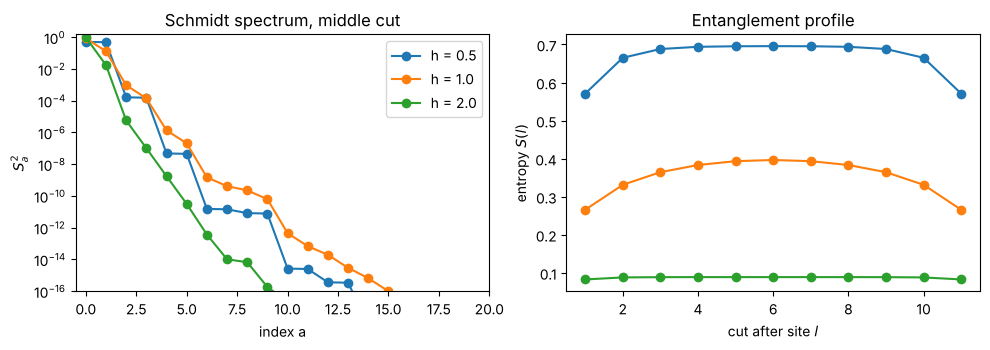

In [5]:
from scipy.sparse.linalg import eigsh

L = 12
# Dense H is 4096 x 4096 here; eigsh finds just the lowest eigenvector.
ground_states = {}
for h in [0.5, 1.0, 2.0]:
    ground_states[h] = eigsh(dmrg.mpo_to_dense(dmrg.tfim_mpo(L, h)), k=1, which="SA")[1][:, 0]


fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for h in [0.5, 1.0, 2.0]:
    S = dmrg.schmidt_values(dmrg.from_dense(ground_states[h], L))
    ax[0].semilogy(S[L // 2 - 1] ** 2, "o-", label=f"h = {h}")
    ax[1].plot(range(1, L), [dmrg.entropy(s) for s in S], "o-", label=f"h = {h}")
ax[0].set(xlabel="index a", ylabel="$S_a^2$", title="Schmidt spectrum, middle cut", ylim=(1e-16, 1.5), xlim=(-0.5, 20))
ax[1].set(xlabel="cut after site $l$", ylabel="entropy $S(l)$", title="Entanglement profile")
ax[0].legend()
plt.tight_layout()

The Schmidt spectrum drops exponentially, fastest deep in a phase. At $h = 0.5$ the ground state is close to a cat state $(|\!\uparrow\uparrow\cdots\rangle + |\!\downarrow\downarrow\cdots\rangle)/\sqrt2$, which has two large Schmidt values and $S \approx \log 2$. At the critical point $h = 1$ the entropy grows logarithmically with $l$ instead of saturating (notebook 3).

## Truncation: how small can $\chi$ be?

Keeping the $\chi$ largest Schmidt values on every bond is the optimal low-rank approximation of each cut (Eckart–Young). Measure the fidelity with the exact state:

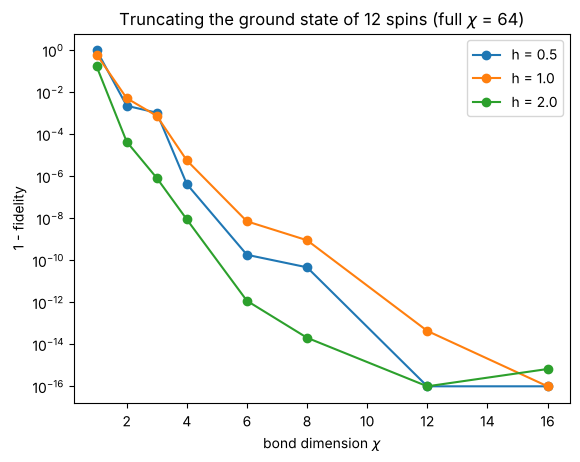

In [6]:
chis = [1, 2, 3, 4, 6, 8, 12, 16]
for h in [0.5, 1.0, 2.0]:
    psi = ground_states[h]
    err = [1 - abs(dmrg.to_dense(dmrg.compress(dmrg.from_dense(psi, L), chi)) @ psi) ** 2 for chi in chis]
    plt.semilogy(chis, np.maximum(err, 1e-16), "o-", label=f"h = {h}")
plt.xlabel(r"bond dimension $\chi$")
plt.ylabel("1 - fidelity")
plt.legend()
plt.title(f"Truncating the ground state of {L} spins (full $\\chi$ = {2 ** (L // 2)})");

With $\chi = 4$ instead of $64$, the critical ground state is already reproduced to about $10^{-5}$, and $\chi = 8$ gives $10^{-9}$. That is why an MPS ansatz with modest $\chi$ works, and DMRG is the algorithm that finds the best such MPS **without** ever building the $2^L$ vector.

## Exercises

1. Build the MPS of the W state $(|100\cdots\rangle + |010\cdots\rangle + \dots)/\sqrt{L}$. What bond dimension does it need? (Answer: 2.)
2. Show that the number of parameters of an MPS is about $L d \chi^2$, and compare with $d^L$ for $L = 100$, $\chi = 64$.
3. In `schmidt_values`, why must the MPS be right-canonical before the left-to-right SVD sweep?